# 00 · Data audit and image basics

**ScalpTrack — Explainable Scalp Condition Classification and Experimental Hair Measurement**
**Owner:** Member B (data audit & classification) · **Labs:** 1 (reading, displaying, resizing, grayscale, pixel analysis)
**Requirements:** REQ-01 (load/validate, keep original geometry), REQ-11 (explicit missing-input status), REQ-12 (reproducibility); spec Sections 4.3–4.4 and 8.1.

### Objective
1. Record exactly which linked public sources exist, what they contain and under which license.
2. Audit the downloaded primary export: counts, classes, formats, corrupt files, dimensions, duplicates, labels.
3. Build the **data manifest** (one row per original image) and a **leakage-safe split manifest**.
4. Demonstrate the Lab 1 operations and why measurement must use native-resolution pixels.

### Input assumptions
* Only the public sources linked in the specification are used (Kaggle *Hair Diseases*, Roboflow *Maheshwariss HAIR AND SCALP*, Roboflow *Litmers scalp*).
* Downloads need the user's own Kaggle/Roboflow account, so this notebook must also run **without** the data and say what is missing.
* Synthetic images appear only as clearly labelled software fixtures and never enter a real split.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

# Robust project-root discovery: works from notebooks/ or the project root, installed or not.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs" / "default.yaml").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scalptrack.config import load_config, seed_everything, project_path, display_path
from scalptrack.demo_data import dataset_status, development_images, synthetic_closeups, figure_path
import json
import cv2
from scalptrack import audit
from scalptrack.io_utils import load_image, describe_array, pixel_neighbourhood, compare_resize_methods, save_rgb
from scalptrack.preprocessing import to_gray

cfg = load_config()
rng = seed_everything(cfg["seed"])
NB = "00_data_audit_basics"
rel = lambda p: display_path(p, ROOT)  # noqa: E731 - short path for printing
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
print("project root:", ROOT)
print("config:", Path(cfg["config_path"]).name, "| seed:", cfg["seed"])

project root: C:\Riddhi_Projects\ScalpTrack
config: default.yaml | seed: 42


In [2]:
def save_fig(fig, name, provenance):
    """Save under outputs/figures/<NB>/<real|synthetic>/ ; synthetic figures get a caption and SYNTHETIC_ prefix."""
    from scalptrack.viz import synthetic_banner
    if provenance == "synthetic":
        synthetic_banner(fig)
    p = figure_path(cfg, NB, name, provenance)
    fig.savefig(p, dpi=120, bbox_inches="tight")
    print("saved", rel(p))
    return p

## 1. Source registry

Each configured source with its task type, license and whether files are present locally. A listing's image
count is **not** a verified count of independent patients or original photographs.

In [3]:
rows = []
for name, s in cfg["datasets"]["sources"].items():
    st = dataset_status(cfg, name)
    rows.append({"source": name, "task_type": s["task_type"], "license": s["license"], "local_files": st["n_files"],
                 "audited": st["audited"], "url": s["url"]})
registry = pd.DataFrame(rows)
registry

,source,task_type,license,local_files,audited,url
0,kaggle_hair_diseases,image_classification,CC BY-NC-SA 4.0,0,False,https://www.kaggle.com/datasets/sundarannamala...
1,maheshwariss_hair_and_scalp,region_classification,CC BY 4.0,0,False,https://universe.roboflow.com/maheshwariss-wor...
2,litmers_scalp,demonstration_only,CC BY 4.0,0,False,https://universe.roboflow.com/litmers-cwywf/sc...


### 1.1 Publisher listing metadata (retrieved, not downloaded)

The Kaggle public API exposes the file *listing* of `sundarannamalai/hair-diseases` without login, while the
image download requires the user's credentials. The listing was saved to
`data/manifests/kaggle_hair_diseases_remote_inventory.csv`. It is metadata about the remote export, **not** an
audit of decoded images.

12000 files listed, extensions: {'jpg': 12000}
total listed size: 591.6 MB


publisher_split,test,train,val,total
raw_label,,,,
Alopecia Areata,120,960,120,1200
Contact Dermatitis,120,960,120,1200
Folliculitis,120,960,120,1200
Head Lice,120,960,120,1200
Lichen Planus,120,960,120,1200
Male Pattern Baldness,120,960,120,1200
Psoriasis,120,960,120,1200
Seborrheic Dermatitis,120,960,120,1200
Telogen Effluvium,120,960,120,1200


saved outputs/figures/00_data_audit_basics/real/kaggle_listing_class_split_counts.png


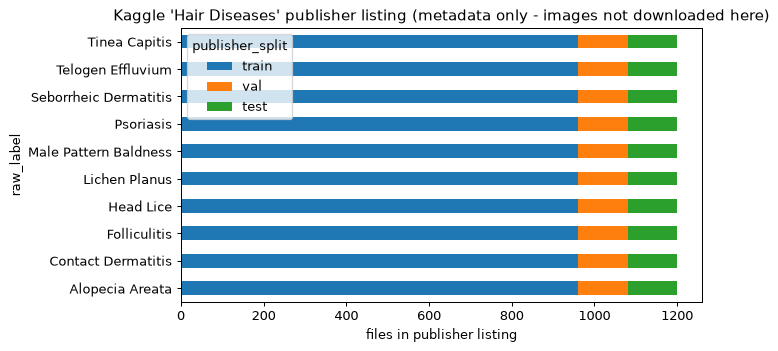

In [4]:
inv_path = project_path(cfg, "manifests", "kaggle_hair_diseases_remote_inventory.csv")
if inv_path.is_file():
    inv = pd.read_csv(inv_path)
    parts = inv["remote_path"].str.split("/", expand=True)
    inv["publisher_split"], inv["raw_label"] = parts[1], parts[2]
    listing = inv.pivot_table(index="raw_label", columns="publisher_split", values="remote_path", aggfunc="count")
    listing["total"] = listing.sum(axis=1)
    print(f"{len(inv)} files listed, extensions: {inv['remote_path'].str.rsplit('.', n=1).str[-1].value_counts().to_dict()}")
    print(f"total listed size: {inv['total_bytes'].sum() / 1e6:.1f} MB")
    display(listing)
    fig, ax = plt.subplots(figsize=(8, 4))
    listing[["train", "val", "test"]].plot.barh(stacked=True, ax=ax)
    ax.set_xlabel("files in publisher listing")
    ax.set_title("Kaggle 'Hair Diseases' publisher listing (metadata only - images not downloaded here)")
    plt.tight_layout()
    save_fig(fig, "kaggle_listing_class_split_counts", "real")
    plt.show()
else:
    print("Remote inventory not recorded; see docs/dataset_setup.md")

**Observation.** The listing shows 10 folder labels with *exactly* 960 / 120 / 120 files each. Perfectly equal
counts in a medical image collection usually indicate curation or augmentation (flipped/rotated copies). That
makes the duplicate/near-duplicate check in Section 3 mandatory before the publisher split can be trusted: a
flipped copy of a training image inside the test set would inflate accuracy.

## 2. Is the primary dataset present?

In [5]:
STATUS = dataset_status(cfg)
print(STATUS["message"])
REAL = STATUS["available"]
DEV = development_images(cfg, n_per_class=1, max_total=4) if REAL else []
SYN = synthetic_closeups(cfg)
print(f"real development images loaded: {len(DEV)} (train/validation only) | synthetic fixtures: {list(SYN)}")

REAL DATASET NOT AVAILABLE - synthetic fixtures are used below.
Dataset 'kaggle_hair_diseases' was not found or contains no images.
Download it from https://www.kaggle.com/datasets/sundarannamalai/hair-diseases (license: CC BY-NC-SA 4.0) and extract it so that:
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\train\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\val\<Class Name>\*.jpg
  C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<optional wrapper folder>\test\<Class Name>\*.jpg
  (or, without a publisher split: C:\Riddhi_Projects\ScalpTrack\data\raw\kaggle_hair_diseases\<Class Name>\*.jpg)
See docs/dataset_setup.md for step-by-step instructions.


real development images loaded: 0 (train/validation only) | synthetic fixtures: ['clean', 'flakes', 'shadow', 'glare', 'light_hair', 'blurred']


## 3. Audit and manifest (runs only when the export is present)

`audit.build_manifest` decodes every file (Pillow, EXIF-corrected), records size/channels/format, SHA-256 and a
64-bit dHash under the 8 flips/90° rotations, joins exact and near-duplicates with union-find, excludes corrupt,
tiny, unlabelled and label-conflicting images, and then **keeps the publisher split only if no duplicate group
crosses it** — otherwise it re-splits ≈70/15/15 by independent group, stratified by class.

In [6]:
MANIFEST, REPORT = None, None
if STATUS["downloaded"]:
    MANIFEST, REPORT = audit.build_manifest(cfg, STATUS["source"])
    paths = audit.save_manifest(MANIFEST, REPORT, project_path(cfg, "manifests"))
    print(json.dumps({k: str(rel(v)) for k, v in paths.items()}, indent=2))
    print(json.dumps({k: REPORT[k] for k in ("n_image_files", "n_other_files", "n_unreadable", "n_missing_label",
                                             "n_label_conflict", "duplicates", "split")}, indent=2, default=str))
else:
    print("Skipped: dataset not downloaded. Follow docs/dataset_setup.md, then re-run this notebook.")

Skipped: dataset not downloaded. Follow docs/dataset_setup.md, then re-run this notebook.


In [7]:
if MANIFEST is not None:
    usable = MANIFEST[MANIFEST["split"].isin(audit.SPLITS)]
    display(audit.split_count_table(MANIFEST))
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    usable.groupby(["canonical_label", "split"]).size().unstack(fill_value=0).plot.barh(stacked=True, ax=axes[0])
    axes[0].set_title("Images per class and split (after audit)")
    axes[1].hist(usable["width_px"], bins=40, alpha=.7, label="width")
    axes[1].hist(usable["height_px"], bins=40, alpha=.7, label="height")
    axes[1].legend(); axes[1].set_title("Native image dimensions (px)")
    usable.boxplot(column="gray_mean", by="canonical_label", ax=axes[2], rot=70)
    axes[2].set_title("Mean grayscale intensity by label"); fig.suptitle("")
    plt.tight_layout(); save_fig(fig, "audit_overview", "real"); plt.show()
    excl = MANIFEST["exclusion_reason"].value_counts(dropna=True)
    print("exclusions:", excl.to_dict() or "none")
    print("formats:", MANIFEST["format"].value_counts().to_dict(), "| modes:", MANIFEST["mode"].value_counts().to_dict())
    imb = usable["canonical_label"].value_counts()
    print(f"class imbalance ratio (max/min): {imb.max() / imb.min():.2f}")

### 3.1 Sample grid and duplicate clusters

In [8]:
if MANIFEST is not None:
    base = ROOT / cfg["datasets"]["sources"][STATUS["source"]]["dir"]
    usable = MANIFEST[MANIFEST["split"].isin(["train", "validation"])]
    labels = sorted(usable["canonical_label"].unique())
    fig, axes = plt.subplots(len(labels), 4, figsize=(10, 2.4 * len(labels)), squeeze=False)
    for i, lab in enumerate(labels):
        rows = usable[usable["canonical_label"] == lab].sample(min(4, (usable["canonical_label"] == lab).sum()), random_state=cfg["seed"])
        for j, ax in enumerate(axes[i]):
            ax.axis("off")
            if j < len(rows):
                ax.imshow(load_image(base / rows.iloc[j]["relative_path"]).rgb)
                ax.set_title(rows.iloc[j]["raw_label"][:28], fontsize=8)
    plt.tight_layout(); save_fig(fig, "sample_grid_by_class", "real"); plt.show()

    sizes = MANIFEST.groupby("duplicate_group_id").size().sort_values(ascending=False)
    big = sizes[sizes > 1].head(3)
    print(f"duplicate groups with >1 member: {(sizes > 1).sum()}  largest: {sizes.max()}")
    for gid in big.index:
        members = MANIFEST[MANIFEST["duplicate_group_id"] == gid].head(6)
        fig, axes = plt.subplots(1, len(members), figsize=(2.6 * len(members), 2.8), squeeze=False)
        for ax, (_, r) in zip(axes[0], members.iterrows()):
            ax.imshow(load_image(base / r["relative_path"]).rgb); ax.axis("off")
            ax.set_title(f"{r['publisher_split']}/{r['raw_label'][:14]}", fontsize=7)
        fig.suptitle(f"duplicate cluster {gid} (review manually: a hash match is evidence, not proof)", fontsize=9)
        save_fig(fig, f"duplicate_cluster_{gid}", "real"); plt.show()
else:
    print("Skipped: no manifest.")

Skipped: no manifest.


## 4. Why grouping matters — a controlled leakage demonstration (synthetic)

Real duplicates cannot be shown without the download, so the mechanism is demonstrated on generated fixtures:
30 synthetic "sources" per class, each with 3 flipped/rotated variants that share a `group_id` — exactly what
augmented public datasets look like. A naive random split scatters variants of one source across train/test;
the grouped split never does. Notebook 05 measures the accuracy inflation this causes.

In [9]:
from scalptrack import synthetic as syn
from scalptrack.audit import grouped_stratified_split
samples = syn.synthetic_classification_set(n_sources_per_class=30, variants_per_source=3, seed=cfg["seed"])
demo = pd.DataFrame([{k: s[k] for k in ("image_id", "label", "group_id")} for s in samples])
naive = pd.Series(np.random.default_rng(cfg["seed"]).choice(["train", "validation", "test"], len(demo), p=[.7, .15, .15]))
grouped = grouped_stratified_split(demo["group_id"], demo["label"], (0.7, 0.15, 0.15), cfg["seed"])
leak = pd.DataFrame({
    "split method": ["naive random (per image)", "grouped (per source)"],
    "groups spanning >1 split": [int((demo.assign(s=naive).groupby("group_id")["s"].nunique() > 1).sum()),
                                 int((demo.assign(s=grouped.values).groupby("group_id")["s"].nunique() > 1).sum())],
    "total groups": demo["group_id"].nunique(),
})
leak

,split method,groups spanning >1 split,total groups
0,naive random (per image),56,90
1,grouped (per source),0,90


## 5. Lab 1 — reading, displaying, resizing, grayscale and pixel analysis

One development image (train/validation, never test) if the dataset is present, plus a synthetic close-up.
OpenCV decodes **BGR**; the package always converts to **RGB** for display and models.

--- closeup [synthetic] ---


,shape,dtype,channels,min,max,mean
array,,,,,,
cv2.imread (BGR),"(200, 200, 3)",uint8,3,18.0,248.0,157.491817
load_image (RGB),"(200, 200, 3)",uint8,3,18.0,248.0,157.491817
grayscale (BT.601),"(200, 200)",uint8,1,29.0,206.0,160.030575


saved outputs/figures/00_data_audit_basics/synthetic/SYNTHETIC_lab1_read_display_closeup.png


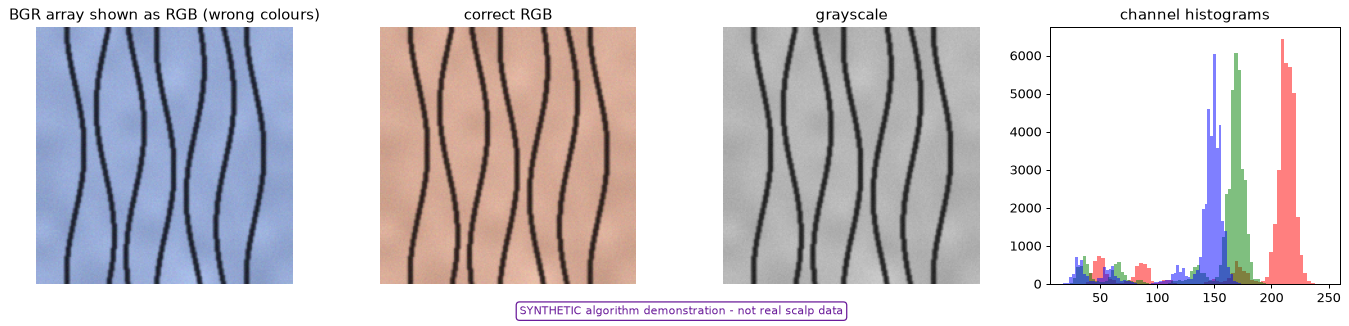

5x5 grayscale neighbourhood at image centre (raw uint8 values):


,0,1,2,3,4
0,182,185,180,184,181
1,181,183,186,187,182
2,182,184,184,189,185
3,185,186,182,184,187
4,184,182,185,189,182


In [10]:
examples = [(d["rgb"], d["image_id"], "real") for d in DEV[:1]] + [(SYN["clean"]["rgb"], "closeup", "synthetic")]
for rgb, name, prov in examples:
    tmp = project_path(cfg, "results", "lab1", f"{name}.png"); save_rgb(tmp, rgb)
    bgr = cv2.imread(str(tmp))
    rec = load_image(tmp)
    info = pd.DataFrame([describe_array(bgr) | {"array": "cv2.imread (BGR)"},
                         describe_array(rec.rgb) | {"array": "load_image (RGB)"},
                         describe_array(to_gray(rec.rgb)) | {"array": "grayscale (BT.601)"}]).set_index("array")
    print(f"--- {name} [{prov}] ---"); display(info)
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
    axes[0].imshow(bgr); axes[0].set_title("BGR array shown as RGB (wrong colours)")
    axes[1].imshow(rec.rgb); axes[1].set_title("correct RGB")
    axes[2].imshow(to_gray(rec.rgb), cmap="gray", vmin=0, vmax=255); axes[2].set_title("grayscale")
    for ch, col in zip(range(3), "rgb"):
        axes[3].hist(rec.rgb[..., ch].ravel(), bins=64, color=col, alpha=.5)
    axes[3].set_title("channel histograms")
    for a in axes[:3]: a.axis("off")
    plt.tight_layout(); save_fig(fig, f"lab1_read_display_{name}", prov); plt.show()
    y, x = rec.height_px // 2, rec.width_px // 2
    print("5x5 grayscale neighbourhood at image centre (raw uint8 values):")
    display(pd.DataFrame(pixel_neighbourhood(to_gray(rec.rgb), x, y, 2)))

saved outputs/figures/00_data_audit_basics/synthetic/SYNTHETIC_lab1_resize_comparison_closeup.png


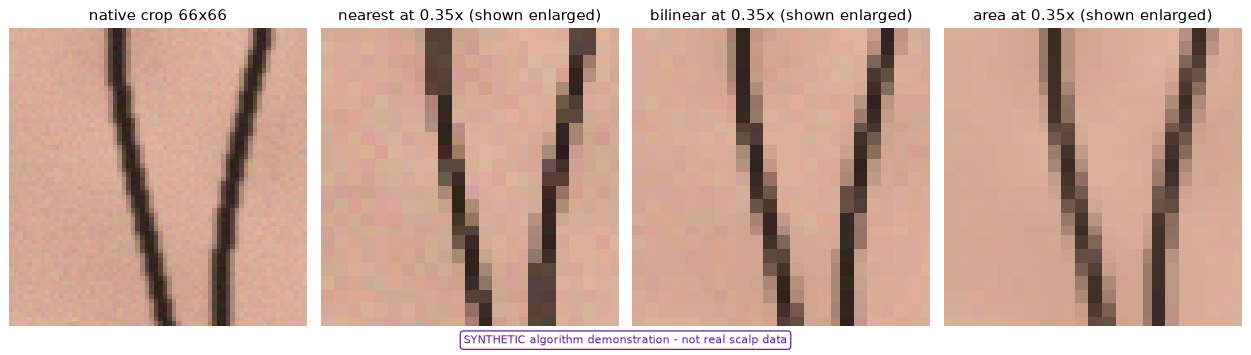

In [11]:
rgb, name, prov = examples[-1] if not DEV else examples[0]
crop = rgb[: rgb.shape[0] // 3, : rgb.shape[1] // 3]
res = compare_resize_methods(crop, 0.35)
up = {k: cv2.resize(v, crop.shape[1::-1], interpolation=cv2.INTER_NEAREST) for k, v in res.items()}
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
axes[0].imshow(crop); axes[0].set_title(f"native crop {crop.shape[1]}x{crop.shape[0]}")
for ax, (k, v) in zip(axes[1:], up.items()):
    ax.imshow(v); ax.set_title(f"{k} at 0.35x (shown enlarged)")
for a in axes: a.axis("off")
plt.tight_layout(); save_fig(fig, f"lab1_resize_comparison_{name}", prov); plt.show()

**Why measurement uses native pixels.** Nearest-neighbour keeps hard but jagged edges, bilinear blurs them, and
area averaging is the best anti-aliased reduction. All three change the number of pixels across a shaft, so the
classifier may use a resized copy while counting/width must run on the native ROI. The check below measures the
same synthetic 5-px shaft at native size and after a 0.5× area resize (scale inverted afterwards).

In [12]:
from scalptrack import measurements as ms
from scalptrack.segmentation import threshold_otsu
f = syn.straight_shafts(3, 5.0, 90.0, size=200)
img = syn.render_hair_image(f["mask"], noise_sigma=0, blur_sigma=0.5, seed=1)
rows = []
for scale in (1.0, 0.5, 0.25):
    small = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale != 1 else img
    mask, _ = threshold_otsu(to_gray(small))
    w = ms.estimate_shaft_width(mask, cfg, "synthetic")
    med = w["median_px"]
    rows.append({"scale": scale, "median_width_px_at_scale": med,
                 "width_mapped_back_to_native_px": None if med is None else med / scale,
                 "true_native_width_px": 5.0, "valid_samples": w["valid_samples"]})
pd.DataFrame(rows)

,scale,median_width_px_at_scale,width_mapped_back_to_native_px,true_native_width_px,valid_samples
0,1.00,6.0,6.0,5.0,568
1,0.50,4.0,8.0,5.0,266
2,0.25,2.0,8.0,5.0,118


Down-scaling quantises the shaft to very few pixels, so the error after mapping back grows with the reduction
factor — the spec's rule "record all crop/resize transforms and invert isotropic scale" is necessary but not
sufficient; measuring on the native ROI is the safe default.

## 6. Capability audit

In [13]:
cap = audit.capability_audit(MANIFEST)
cap_path = project_path(cfg, "manifests", "capability_audit.csv"); cap.to_csv(cap_path, index=False)
print("saved", rel(cap_path)); cap

saved data/manifests/capability_audit.csv


,capability,status,reason
0,condition classification labels,unavailable,dataset not downloaded
1,independent patient identity,unavailable,no patient_id supplied by the source; grouping...
2,hair instance / count labels,unavailable,dataset not downloaded
3,segmentation masks,unavailable,none in export
4,physical pixel scale (um/px),unavailable,no documented scale; widths stay in pixels
5,calibrated stereo pairs,unavailable,no verified pair/calibration; synthetic stereo...
6,face-containing images (Haar positive case),to be checked in notebook 07,requires running the detector over the downloa...


## 7. Limitations and edge cases
* **No patient identity** is supplied by any linked source; grouping by duplicate cluster prevents copy leakage
  but cannot prevent two *different* photos of the same person landing in different splits.
* dHash with flips/rotations catches common augmentations, not crops, colour jitter or strong rescaling. Clusters
  must be reviewed visually; a hash match is evidence, not proof.
* Folder labels are publisher labels without clinical adjudication. Raw names are preserved in `raw_label`.
* Absent physical scale and stereo relations are stored as **null**, never guessed.
* If the data is not downloaded, Sections 3 and the real-image parts of Section 5 are skipped with a message;
  everything else still runs.

## 8. Conclusion
The audit machinery (scanning, decoding checks, duplicate grouping, label-conflict exclusion, grouped splits and
manifests with the spec's fields) is implemented and tested on fixtures. Real counts are only reported once the
export is downloaded; the publisher listing already shows a perfectly balanced structure that justifies the
leakage checks.

**References:** spec Sections 4 and 8.1; OpenCV colour conversions and histogram docs; Pillow `ImageOps.exif_transpose`.